# MagiV2 Sequence Identity Notebook

This notebook lets you:

- choose any 3-page sequence folder
- view the original sequence pages
- run MagiV2 once
- inspect MagiV2 outputs
- extract character crop embeddings
- use MagiV2 page-local character clusters (`CL`)
- build sequence-wide identities (`S`)
- match clusters sequentially using **best member-to-member cosine similarity**
- annotate each sequence-wide identity `S` in a different color

Naming used everywhere:

- `PG1:C1` = character detection C1 on page 1
- `PG1:CL1` = page-local MagiV2 cluster 1 on page 1
- `S1` = sequence-wide identity

In [4]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import AutoModel

MODEL_PATH = r"C:\MODELS\magiv2"

model = AutoModel.from_pretrained(
    MODEL_PATH,
    trust_remote_code=True,
    local_files_only=True,
).cuda().eval()

print(type(model))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\module.py:2593: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  module._load_from_state_dict(
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\batchnorm.py:141: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (D

<class 'transformers_modules.magiv2.modelling_magiv2.Magiv2Model'>


In [5]:
def read_image(path):
    with open(path, "rb") as f:
        return np.array(Image.open(f).convert("L").convert("RGB"))

## CHOOSE-SEQUENCE

In [6]:
SEQUENCE_ROOT = Path(
    r"C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc"
)

PAGE_FILES = sorted(SEQUENCE_ROOT.glob("*.png"))
chapter_pages = [read_image(p) for p in PAGE_FILES]

print("Sequence:", SEQUENCE_ROOT.name)
print("Pages:", [p.name for p in PAGE_FILES])

Sequence: seq_0dc2e3d874c804fc
Pages: ['01.png', '02.png', '03.png']


## VIEW-SEQUENCE

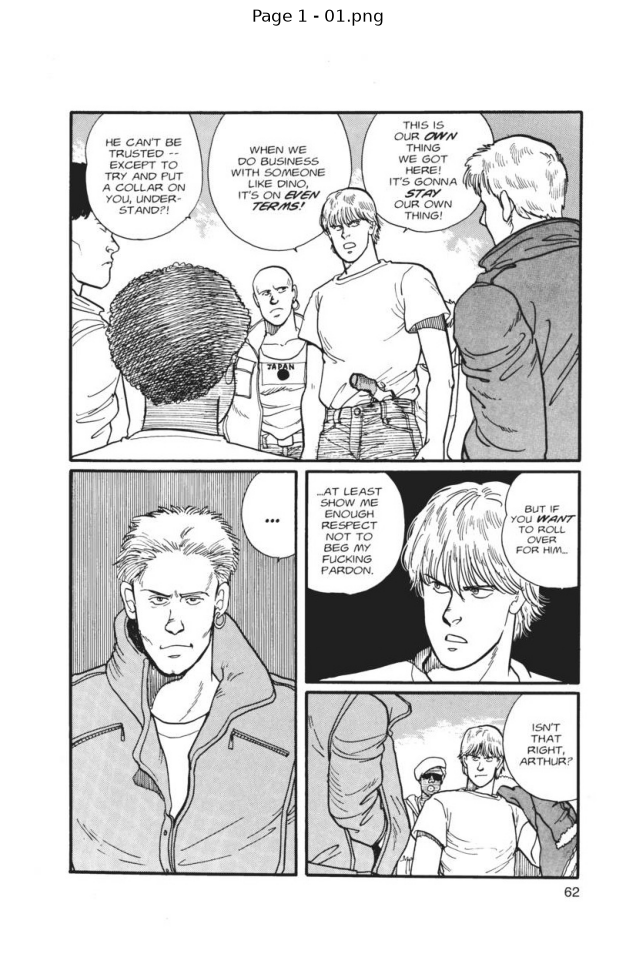

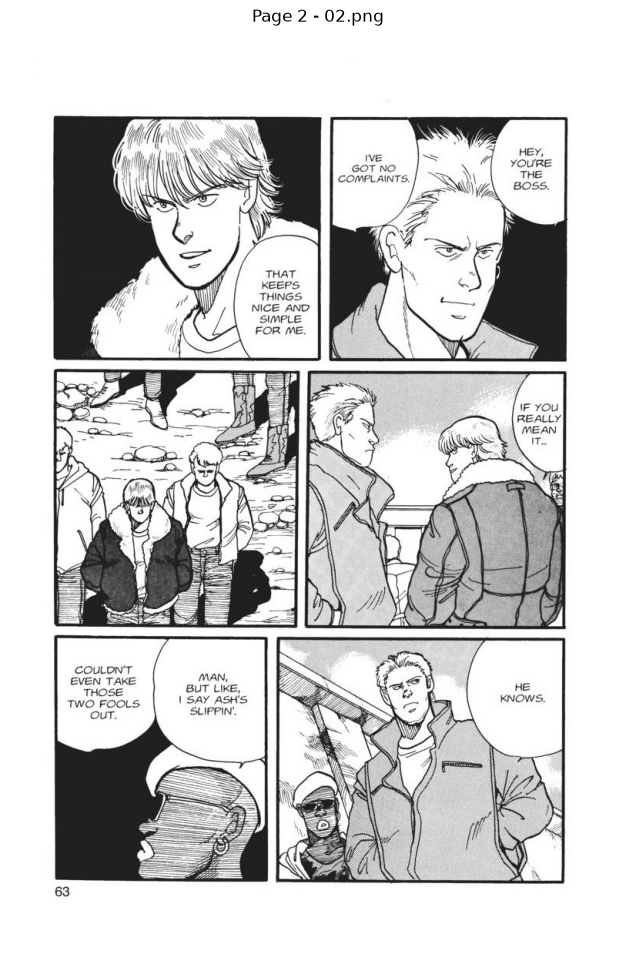

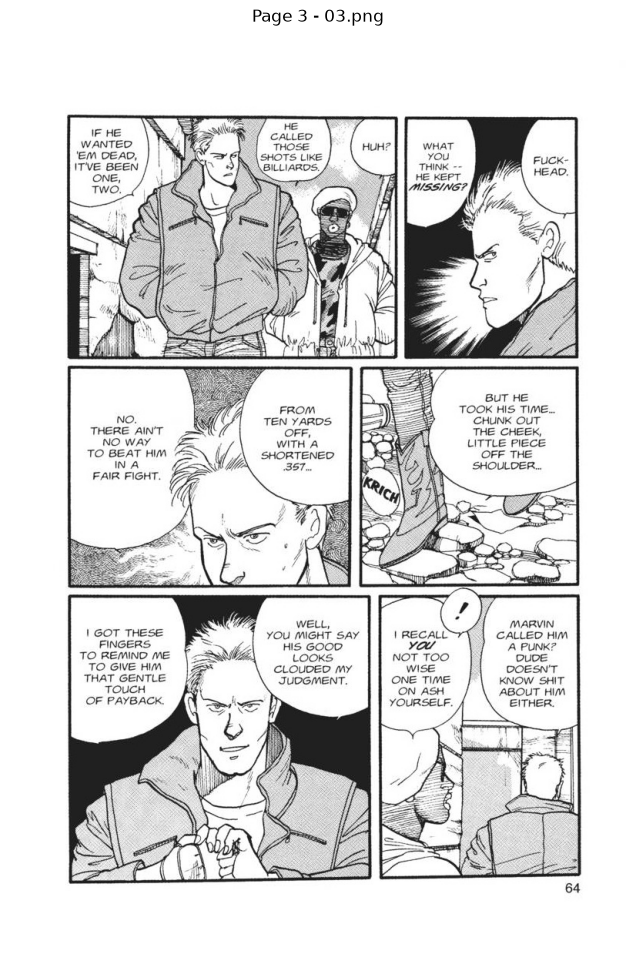

In [7]:
def view_sequence(chapter_pages, page_files=None):
    for i, image in enumerate(chapter_pages):
        plt.figure(figsize=(8, 12))
        plt.imshow(image)
        title = f"Page {i+1}"
        if page_files is not None:
            title += f" - {page_files[i].name}"
        plt.title(title)
        plt.axis("off")
        plt.show()

view_sequence(chapter_pages, PAGE_FILES)

## RUN-MAGIV2

In [8]:
character_bank = {
    "images": [],
    "names": [],
}

with torch.no_grad():
    per_page_results = model.do_chapter_wide_prediction(
        chapter_pages,
        character_bank,
        use_tqdm=True,
        do_ocr=True,
    )

print(per_page_results[0].keys())

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:04<00:00,  4.74s/it]

dict_keys(['panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text', 'ocr', 'character_names'])


## BASIC-MAGIV2-OUTPUTS

In [12]:
def center(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, (y1 + y2) / 2)

def draw_box(ax, box, edgecolor, label=None, linewidth=2, linestyle="-"):
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=linewidth,
        edgecolor=edgecolor,
        facecolor="none",
        linestyle=linestyle,
    )
    ax.add_patch(rect)

    if label:
        ax.text(
            x1,
            max(0, y1 - 4),
            label,
            fontsize=8,
            bbox=dict(facecolor="black", alpha=0.65, edgecolor="none"),
            color="white",
        )

In [13]:
def annotate_magi_page(
    image,
    result,
    page_idx,
    show_panels=True,
    show_texts=True,
    show_characters=True,
    show_tails=True,
    show_same_character=True,
    show_text_character=True,
    show_text_tail=True,
    show_ocr=True,
):
    fig, ax = plt.subplots(figsize=(12, 18))
    ax.imshow(image)

    if show_panels:
        for i, box in enumerate(result["panels"]):
            draw_box(ax, box, "green", f"PG{page_idx+1}:PN{i+1}")

    if show_texts:
        for i, box in enumerate(result["texts"]):
            essential = True
            if i < len(result.get("is_essential_text", [])):
                essential = bool(result["is_essential_text"][i])

            label = f"PG{page_idx+1}:T{i+1}"
            if show_ocr and "ocr" in result and i < len(result["ocr"]):
                txt = result["ocr"][i]
                if len(txt) > 40:
                    txt = txt[:37] + "..."
                label += f" | {txt}"

            draw_box(ax, box, "red" if essential else "gray", label)

    if show_characters:
        labels = result.get("character_cluster_labels", [])
        for i, box in enumerate(result["characters"]):
            cluster_id = int(labels[i]) + 1 if i < len(labels) else None
            label = f"PG{page_idx+1}:C{i+1}"
            if cluster_id is not None:
                label += f" | PG{page_idx+1}:CL{cluster_id}"
            draw_box(ax, box, "blue", label)

    if show_tails:
        for i, box in enumerate(result["tails"]):
            draw_box(ax, box, "purple", f"PG{page_idx+1}:TAIL{i+1}")

    if show_same_character:
        labels = result.get("character_cluster_labels", [])
        groups = {}
        for i, label in enumerate(labels):
            groups.setdefault(int(label), []).append(i)

        for group in groups.values():
            if len(group) < 2:
                continue
            root = group[0]
            x1, y1 = center(result["characters"][root])
            for j in group[1:]:
                x2, y2 = center(result["characters"][j])
                ax.plot([x1, x2], [y1, y2], linewidth=2)

    if show_text_character:
        for text_idx, char_idx in result["text_character_associations"]:
            if text_idx >= len(result["texts"]) or char_idx >= len(result["characters"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["characters"][char_idx])

            ax.plot([x1, x2], [y1, y2], linestyle="--", linewidth=2)

            mx, my = (x1+x2)/2, (y1+y2)/2
            ax.text(
                mx, my,
                f"PG{page_idx+1}:T{text_idx+1}->C{char_idx+1}",
                fontsize=7,
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
            )

    if show_text_tail:
        for text_idx, tail_idx in result["text_tail_associations"]:
            if text_idx >= len(result["texts"]) or tail_idx >= len(result["tails"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["tails"][tail_idx])

            ax.plot([x1, x2], [y1, y2], linestyle=":", linewidth=2)

    ax.set_title(f"MagiV2 outputs - PG{page_idx+1}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

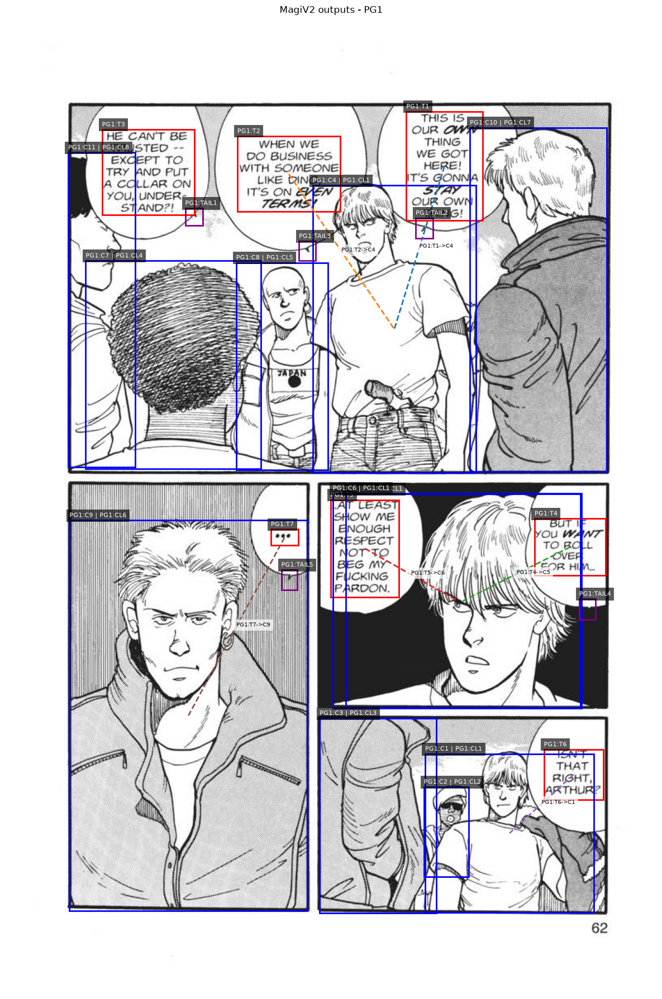

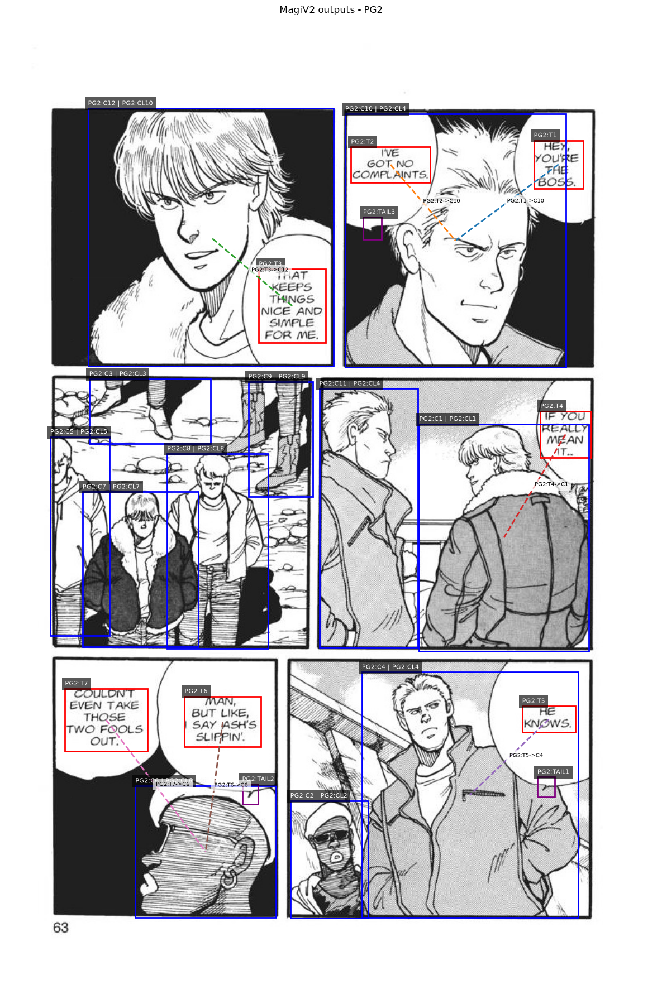

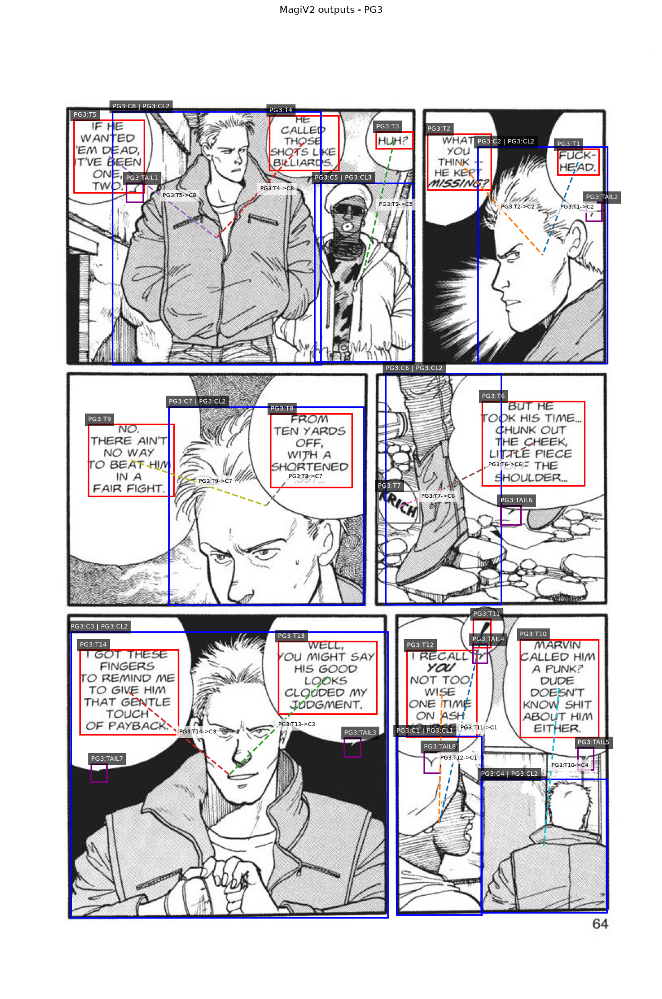

In [30]:
# View MagiV2 annotations for the whole sequence
for page_idx, (image, result) in enumerate(zip(chapter_pages, per_page_results)):
    annotate_magi_page(
        image,
        result,
        page_idx=page_idx,
        show_panels=False,
        show_texts=True,
        show_characters=True,
        show_tails=True,
        show_same_character=False,
        show_text_character=True,
        show_text_tail=False,
        show_ocr=False,
    )

## CROSS-PAGE-CHAR-SIMILARITY

In [15]:
# Extract character crop embeddings from MagiV2
character_boxes = [
    result["characters"]
    for result in per_page_results
]

with torch.no_grad():
    embeddings_per_page = model.predict_crop_embeddings(
        chapter_pages,
        character_boxes,
    )

# L2-normalize so dot product = cosine similarity
embeddings_per_page = [
    torch.nn.functional.normalize(x, p=2, dim=1)
    if len(x) > 0
    else x
    for x in embeddings_per_page
]

for page_idx, emb in enumerate(embeddings_per_page):
    print(
        f"PG{page_idx+1}: "
        f"{len(emb)} detections, "
        f"embedding shape={tuple(emb.shape)}"
    )

PG1: 11 detections, embedding shape=(11, 768)
PG2: 12 detections, embedding shape=(12, 768)
PG3: 8 detections, embedding shape=(8, 768)


In [16]:
def get_page_clusters(page_idx, per_page_results):
    """
    Returns:
    {
        "PG1:CL1": [0, 3, 6],
        "PG1:CL2": [1]
    }

    Values are character indices.
    """
    labels = per_page_results[page_idx]["character_cluster_labels"]

    clusters = {}

    for char_idx, cluster_idx in enumerate(labels):
        cluster_id = f"PG{page_idx+1}:CL{int(cluster_idx)+1}"
        clusters.setdefault(cluster_id, []).append(char_idx)

    return clusters


for page_idx in range(len(per_page_results)):
    print(f"\nPG{page_idx+1}")
    print(get_page_clusters(page_idx, per_page_results))


PG1
{'PG1:CL1': [0, 3, 4, 5], 'PG1:CL2': [1], 'PG1:CL3': [2], 'PG1:CL4': [6], 'PG1:CL5': [7], 'PG1:CL6': [8], 'PG1:CL7': [9], 'PG1:CL8': [10]}

PG2
{'PG2:CL1': [0], 'PG2:CL2': [1], 'PG2:CL3': [2], 'PG2:CL4': [3, 9, 10], 'PG2:CL5': [4], 'PG2:CL6': [5], 'PG2:CL7': [6], 'PG2:CL8': [7], 'PG2:CL9': [8], 'PG2:CL10': [11]}

PG3
{'PG3:CL1': [0], 'PG3:CL2': [1, 2, 3, 5, 6, 7], 'PG3:CL3': [4]}


In [17]:
def cluster_similarity(
    page_idx,
    char_indices,
    sequence_identity,
    embeddings_per_page,
):
    """
    Similarity between one current page-local CL and one existing S.

    Score = best member-to-member cosine similarity.
    """

    best_score = -1.0
    best_pair = None

    current_embeddings = embeddings_per_page[page_idx]

    for current_char_idx in char_indices:
        current_embedding = current_embeddings[current_char_idx]

        for member in sequence_identity["members"]:
            old_page_idx = member["page_idx"]
            old_char_idx = member["char_idx"]

            old_embedding = embeddings_per_page[old_page_idx][old_char_idx]

            score = torch.dot(
                current_embedding,
                old_embedding
            ).item()

            if score > best_score:
                best_score = score
                best_pair = {
                    "current": f"PG{page_idx+1}:C{current_char_idx+1}",
                    "existing": f"PG{old_page_idx+1}:C{old_char_idx+1}",
                }

    return best_score, best_pair

In [18]:
def clusterize(
    page_numbers,
    per_page_results,
    embeddings_per_page,
    threshold=0.80,
):
    """
    Sequential sequence-level identity clustering.

    Unit of matching:
        page-local MagiV2 cluster (CL)

    Similarity:
        best member-to-member cosine similarity

    Rules:
        - first page initializes S identities
        - next page CLs match against existing S identities
        - one CL can map to only one S
        - one S can receive only one CL from the same page
        - unmatched CL creates a new S
    """

    identified_char = {}
    next_s_id = 1

    # First page initializes sequence identities
    first_page = page_numbers[0]
    first_clusters = get_page_clusters(first_page, per_page_results)

    for cluster_id, char_indices in first_clusters.items():
        s_id = f"S{next_s_id}"
        next_s_id += 1

        identified_char[s_id] = {
            "clusters": [cluster_id],
            "members": []
        }

        for char_idx in char_indices:
            identified_char[s_id]["members"].append({
                "page_idx": first_page,
                "char_idx": char_idx,
                "char_id": f"PG{first_page+1}:C{char_idx+1}",
                "cluster_id": cluster_id,
            })

    # Remaining pages
    for page_idx in page_numbers[1:]:

        current_clusters = get_page_clusters(
            page_idx,
            per_page_results
        )

        candidates = []

        for cluster_id, char_indices in current_clusters.items():

            for s_id, sequence_identity in identified_char.items():

                score, best_pair = cluster_similarity(
                    page_idx,
                    char_indices,
                    sequence_identity,
                    embeddings_per_page,
                )

                if score >= threshold:
                    candidates.append({
                        "score": score,
                        "cluster_id": cluster_id,
                        "s_id": s_id,
                        "best_pair": best_pair,
                    })

        # strongest evidence first
        candidates.sort(
            key=lambda x: x["score"],
            reverse=True
        )

        # Prevent two CLs on same page from collapsing into same S
        used_clusters = set()
        used_s = set()
        accepted_matches = {}

        for candidate in candidates:
            cluster_id = candidate["cluster_id"]
            s_id = candidate["s_id"]

            if cluster_id in used_clusters:
                continue
            if s_id in used_s:
                continue

            accepted_matches[cluster_id] = candidate
            used_clusters.add(cluster_id)
            used_s.add(s_id)

        # Apply matches
        for cluster_id, char_indices in current_clusters.items():

            if cluster_id in accepted_matches:
                match = accepted_matches[cluster_id]
                s_id = match["s_id"]

                identified_char[s_id]["clusters"].append(cluster_id)

                for char_idx in char_indices:
                    identified_char[s_id]["members"].append({
                        "page_idx": page_idx,
                        "char_idx": char_idx,
                        "char_id": f"PG{page_idx+1}:C{char_idx+1}",
                        "cluster_id": cluster_id,
                    })

            else:
                s_id = f"S{next_s_id}"
                next_s_id += 1

                identified_char[s_id] = {
                    "clusters": [cluster_id],
                    "members": []
                }

                for char_idx in char_indices:
                    identified_char[s_id]["members"].append({
                        "page_idx": page_idx,
                        "char_idx": char_idx,
                        "char_id": f"PG{page_idx+1}:C{char_idx+1}",
                        "cluster_id": cluster_id,
                    })

        # Print page decisions
        print(f"\n===== PG{page_idx+1} =====")

        for cluster_id in current_clusters:
            if cluster_id in accepted_matches:
                m = accepted_matches[cluster_id]
                print(
                    f"{cluster_id} -> {m['s_id']} "
                    f"| cosine={m['score']:.3f} "
                    f"| {m['best_pair']['current']} "
                    f"<-> {m['best_pair']['existing']}"
                )
            else:
                for s_id, data in identified_char.items():
                    if cluster_id in data["clusters"]:
                        print(
                            f"{cluster_id} -> {s_id} "
                            f"| NEW IDENTITY"
                        )
                        break

    return identified_char

In [25]:
identified_char = clusterize(
    page_numbers=list(range(len(per_page_results))),
    per_page_results=per_page_results,
    embeddings_per_page=embeddings_per_page,
    threshold=0.5,
)


===== PG2 =====
PG2:CL1 -> S7 | cosine=0.852 | PG2:C1 <-> PG1:C10
PG2:CL2 -> S2 | cosine=0.867 | PG2:C2 <-> PG1:C2
PG2:CL3 -> S3 | cosine=0.755 | PG2:C3 <-> PG1:C3
PG2:CL4 -> S6 | cosine=0.973 | PG2:C10 <-> PG1:C9
PG2:CL5 -> S8 | cosine=0.543 | PG2:C5 <-> PG1:C11
PG2:CL6 -> S5 | cosine=0.767 | PG2:C6 <-> PG1:C8
PG2:CL7 -> S9 | NEW IDENTITY
PG2:CL8 -> S4 | cosine=0.652 | PG2:C8 <-> PG1:C7
PG2:CL9 -> S10 | NEW IDENTITY
PG2:CL10 -> S1 | cosine=0.947 | PG2:C12 <-> PG1:C6

===== PG3 =====
PG3:CL1 -> S5 | cosine=0.837 | PG3:C1 <-> PG2:C6
PG3:CL2 -> S6 | cosine=0.966 | PG3:C8 <-> PG2:C10
PG3:CL3 -> S2 | cosine=0.933 | PG3:C5 <-> PG2:C2


In [26]:
for s_id, data in identified_char.items():
    print(f"\n{s_id}")
    print(" clusters:", data["clusters"])
    print(" members :", [m["char_id"] for m in data["members"]])


S1
 clusters: ['PG1:CL1', 'PG2:CL10']
 members : ['PG1:C1', 'PG1:C4', 'PG1:C5', 'PG1:C6', 'PG2:C12']

S2
 clusters: ['PG1:CL2', 'PG2:CL2', 'PG3:CL3']
 members : ['PG1:C2', 'PG2:C2', 'PG3:C5']

S3
 clusters: ['PG1:CL3', 'PG2:CL3']
 members : ['PG1:C3', 'PG2:C3']

S4
 clusters: ['PG1:CL4', 'PG2:CL8']
 members : ['PG1:C7', 'PG2:C8']

S5
 clusters: ['PG1:CL5', 'PG2:CL6', 'PG3:CL1']
 members : ['PG1:C8', 'PG2:C6', 'PG3:C1']

S6
 clusters: ['PG1:CL6', 'PG2:CL4', 'PG3:CL2']
 members : ['PG1:C9', 'PG2:C4', 'PG2:C10', 'PG2:C11', 'PG3:C2', 'PG3:C3', 'PG3:C4', 'PG3:C6', 'PG3:C7', 'PG3:C8']

S7
 clusters: ['PG1:CL7', 'PG2:CL1']
 members : ['PG1:C10', 'PG2:C1']

S8
 clusters: ['PG1:CL8', 'PG2:CL5']
 members : ['PG1:C11', 'PG2:C5']

S9
 clusters: ['PG2:CL7']
 members : ['PG2:C7']

S10
 clusters: ['PG2:CL9']
 members : ['PG2:C9']


## VIEW-SEQUENCE-IDENTITIES

In [27]:
def build_s_color_map(identified_char):
    cmap = plt.get_cmap(
        "tab20",
        max(len(identified_char), 1)
    )

    return {
        s_id: cmap(i)
        for i, s_id in enumerate(sorted(identified_char.keys()))
    }


def annotate_sequence_identities(
    chapter_pages,
    per_page_results,
    identified_char,
    page_files=None,
    show_text_char=False,
    save_dir=None,
):
    s_to_color = build_s_color_map(identified_char)

    char_to_s = {}
    for s_id, data in identified_char.items():
        for member in data["members"]:
            char_to_s[member["char_id"]] = s_id

    for page_idx, (image, result) in enumerate(zip(chapter_pages, per_page_results)):
        fig, ax = plt.subplots(figsize=(12, 18))
        ax.imshow(image)

        local_labels = result.get("character_cluster_labels", [])

        for char_idx, box in enumerate(result["characters"]):
            char_id = f"PG{page_idx+1}:C{char_idx+1}"
            cluster_id = None

            if char_idx < len(local_labels):
                cluster_id = f"PG{page_idx+1}:CL{int(local_labels[char_idx])+1}"

            s_id = char_to_s.get(char_id, "UNMATCHED")
            color = s_to_color.get(s_id, "white")

            x1, y1, x2, y2 = box

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=3,
                edgecolor=color,
                facecolor="none"
            )
            ax.add_patch(rect)

            label = f"{s_id} | {char_id}"
            if cluster_id is not None:
                label += f" | {cluster_id}"

            ax.text(
                x1,
                max(0, y1 - 5),
                label,
                fontsize=9,
                color="white",
                bbox=dict(
                    facecolor=color,
                    alpha=0.85,
                    edgecolor="none"
                )
            )

        if show_text_char:
            for text_idx, char_idx in result["text_character_associations"]:
                if text_idx >= len(result["texts"]) or char_idx >= len(result["characters"]):
                    continue

                char_id = f"PG{page_idx+1}:C{char_idx+1}"
                s_id = char_to_s.get(char_id, None)

                if s_id is None:
                    continue

                color = s_to_color[s_id]

                tx1, ty1 = center(result["texts"][text_idx])
                cx1, cy1 = center(result["characters"][char_idx])

                ax.plot(
                    [tx1, cx1],
                    [ty1, cy1],
                    linestyle="--",
                    linewidth=2,
                    color=color
                )

        title = f"Sequence identities - PG{page_idx+1}"
        if page_files is not None:
            title += f" - {page_files[page_idx].name}"

        ax.set_title(title)
        ax.axis("off")
        plt.tight_layout()

        if save_dir is not None:
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)

            out_path = save_dir / f"PG{page_idx+1}_sequence_identities.png"
            plt.savefig(
                out_path,
                bbox_inches="tight",
                pad_inches=0.05,
                dpi=150
            )
            print("saved:", out_path)

        plt.show()

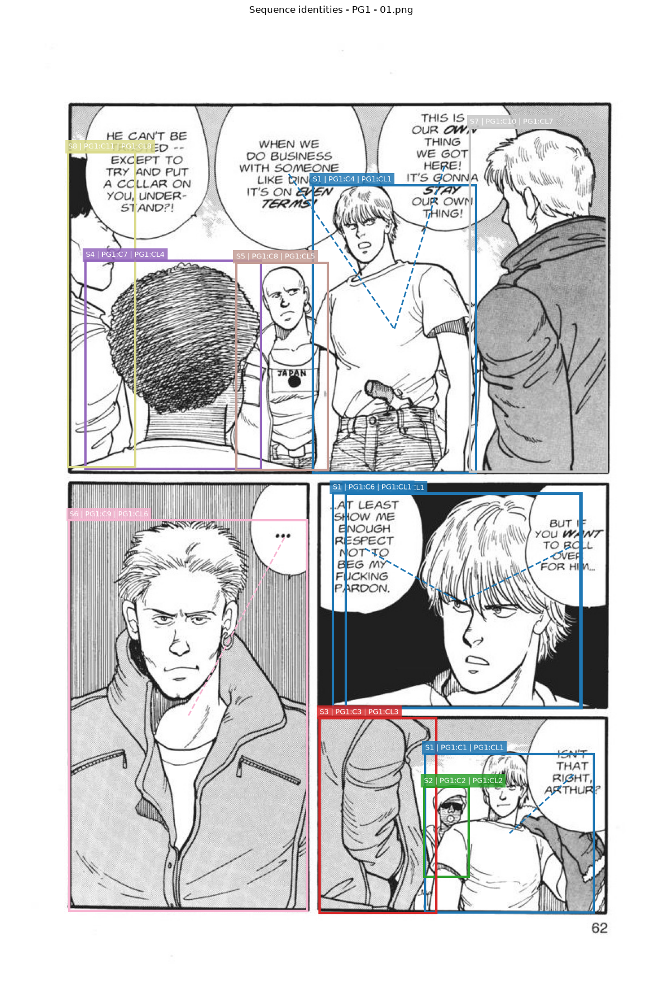

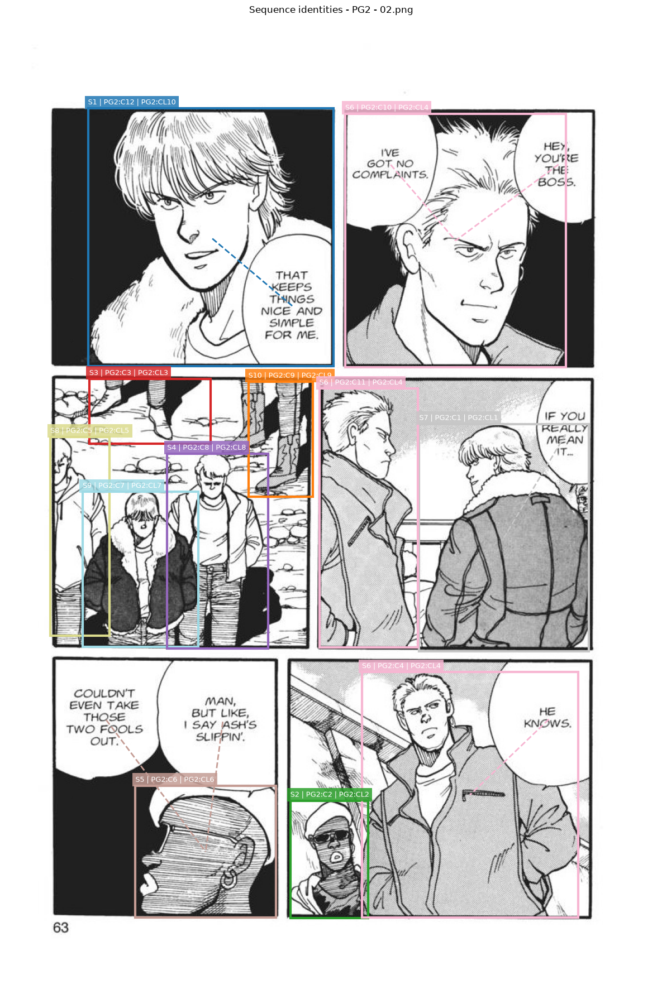

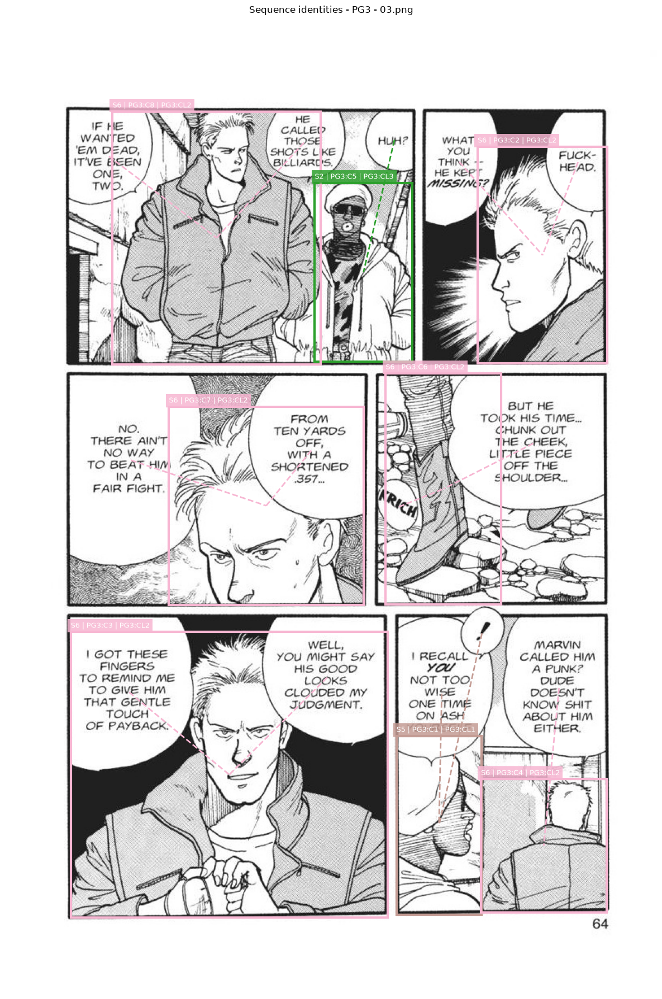

In [28]:
annotate_sequence_identities(
    chapter_pages=chapter_pages,
    per_page_results=per_page_results,
    identified_char=identified_char,
    page_files=PAGE_FILES,
    show_text_char=True,
)

## SAVE-ANNOTATED-SEQUENCE

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc\sequence_identity_annotations\PG1_sequence_identities.png


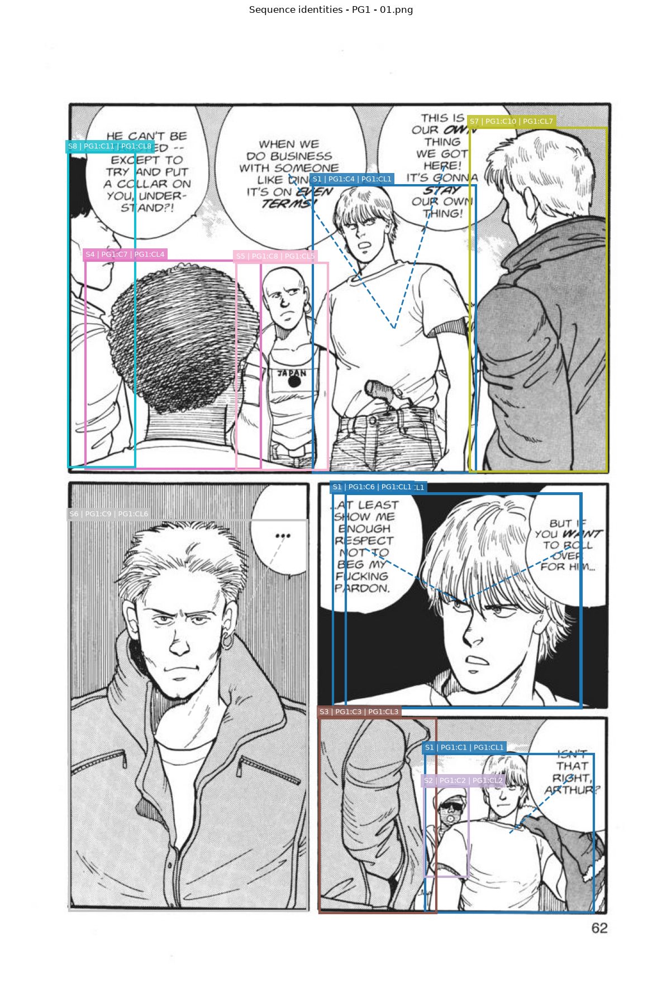

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc\sequence_identity_annotations\PG2_sequence_identities.png


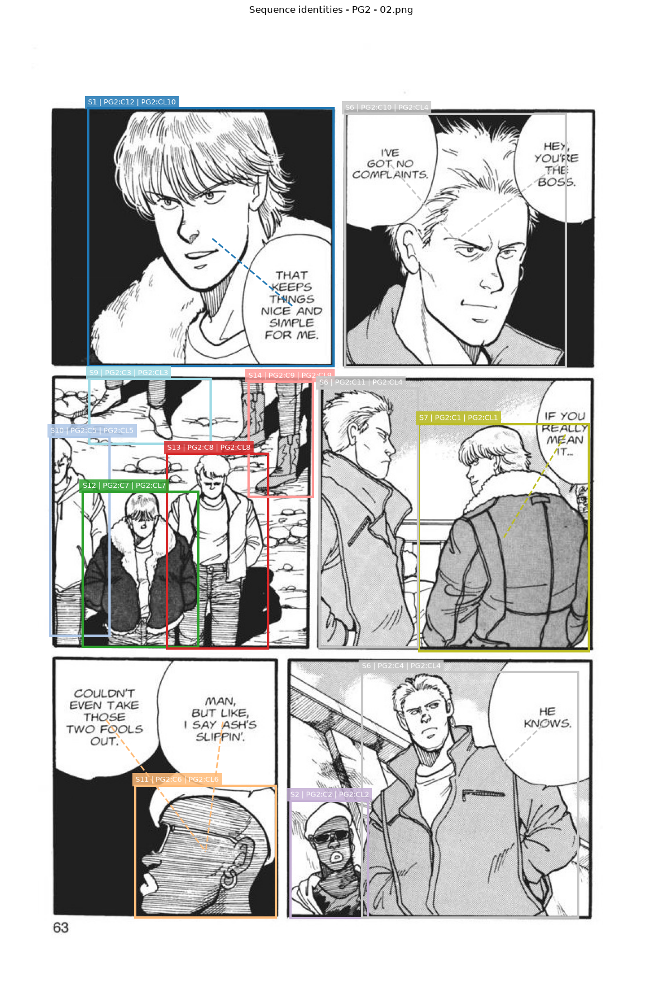

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc\sequence_identity_annotations\PG3_sequence_identities.png


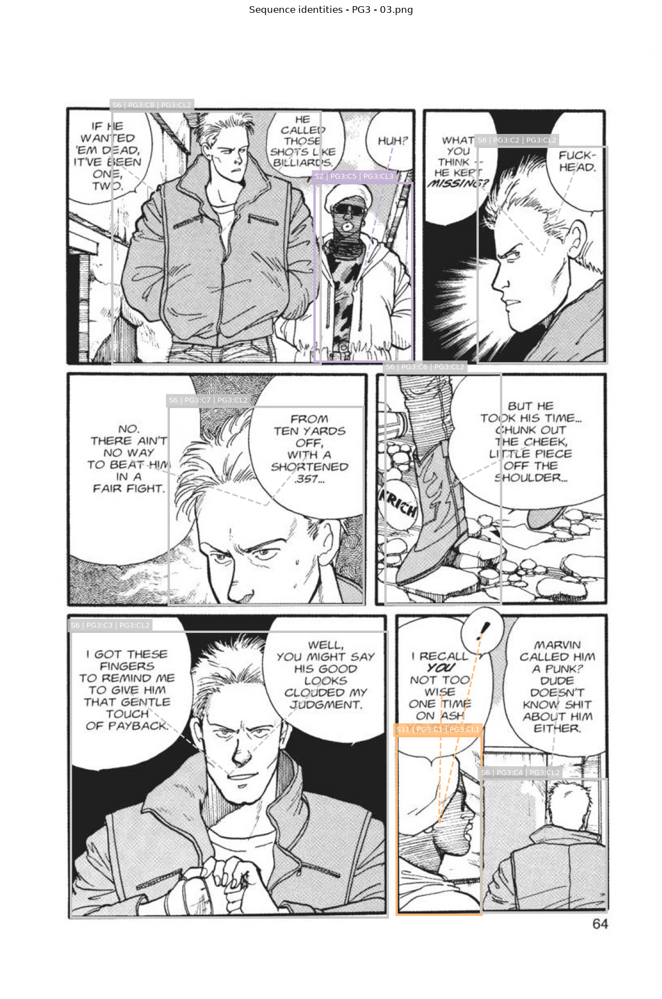

In [18]:
SAVE_DIR = SEQUENCE_ROOT / "sequence_identity_annotations"

annotate_sequence_identities(
    chapter_pages=chapter_pages,
    per_page_results=per_page_results,
    identified_char=identified_char,
    page_files=PAGE_FILES,
    show_text_char=True,
    save_dir=SAVE_DIR,
)